# **4. ENSEMBLE: AdaBoost với các weak learner khác nhau**
---

### **Bảng quy trình xây dựng & đánh giá Ensemble (AdaBoost)**

| Bước | Nội dung thực hiện | Đầu ra / Tệp sinh ra |
|:---:|:---|:---|
| **1** | **Thiết lập môi trường và nạp dữ liệu MNIST đã tiền xử lý** | Cố định `SEED`, xác định `PROJECT_ROOT`, khởi tạo các thư mục đầu ra và cấu hình đồ thị; nạp dữ liệu Min–Max $[0,1]$ từ `data/processed/mnist_processed.npz`, gồm 50.000 Train, 10.000 Validation và 10.000 Test, mỗi ảnh có 784 đặc trưng. |
| **2** | **Cơ sở lý thuyết: AdaBoost và cơ chế kết hợp các weak learner** | Trình bày thuật toán AdaBoost nhị phân: huấn luyện tuần tự, tính lỗi có trọng số, xác định trọng số mô hình, cập nhật trọng số mẫu và kết hợp dự đoán; giải thích Exponential Loss, ưu / nhược điểm và đối chiếu với Bagging, Random Forest, Gradient Boosting. Giới thiệu 4 loại weak learner để thực nghiệm trên MNIST 10 lớp. |
| **3** | **Định nghĩa các mô hình AdaBoost và hàm benchmark** | Dùng Scikit-Learn xây dựng 4 biến thể: Decision Stump (`max_depth = 1`) và Decision Tree (`max_depth = 3`) với `n_estimators = 200`; Logistic Regression (`max_iter = 500`, `solver = lbfgs`) và GaussianNB với `n_estimators = 50`; tất cả dùng `learning_rate = 0.5`. Xây dựng `benchmark` và `evaluate_fitted` để đo Accuracy, Macro Precision, Macro Recall, Macro F1 và thời gian huấn luyện / dự đoán. |
| **4** | **Huấn luyện và đánh giá 4 mô hình trên Train / Validation / Test** | Gọi `benchmark` với `cv = None`: huấn luyện trên Train, đánh giá trên Test và lưu các mô hình vào `fitted_models`; dùng lại các mô hình đã huấn luyện để đánh giá Train / Validation. Tổng hợp `res_train`, `res_val`, `res_test`; lưu biểu đồ so sánh Accuracy tại `figures/4_01_accuracy_comparison.png`. |
| **5** | **Phân tích ma trận nhầm lẫn của mô hình có Test Accuracy cao nhất** | Chọn `best_name` và `best_model` theo Test Accuracy trong `res_test`; vẽ ma trận nhầm lẫn trên cả 3 tập vào `figures/4_02_confusion_matrix_best.png`. Trên Test, tìm cặp chữ số bị nhầm nhiều nhất theo tổng số lỗi hai chiều và thống kê số lỗi theo từng chiều. |
| **6** | **Trực quan hoá độ quan trọng của pixel bằng Random Forest** | Huấn luyện riêng `RandomForestClassifier(n_estimators = 100)` trên Train; đưa `feature_importances_` về ảnh $28 \times 28$, xác định 5 pixel quan trọng nhất và đối chiếu với các đặc trưng có phương sai bằng 0. Lưu bản đồ nhiệt tại `figures/4_03_feature_importances.png`. |
| **7** | **Khảo sát số vòng boosting (`n_estimators`) trên Validation** | Khảo sát `n_estimators = [1, 5, 10, 25, 50, 100, 200]` cho cả 4 loại weak learner, cố định `learning_rate = 0.5`; huấn luyện trên Train và đo Validation Accuracy. So sánh với Decision Stump đơn lẻ; lưu biểu đồ `figures/4_04_n_estimators_analysis.png`. |
| **8** | **Khảo sát tốc độ học (`learning_rate`) trên Validation** | Khảo sát `learning_rate = [0.01, 0.05, 0.1, 0.3, 0.5, 1.0]`; cố định `n_estimators = 100` cho hai biến thể cây và `n_estimators = 50` cho Logistic Regression / GaussianNB. So sánh Validation Accuracy với Decision Stump đơn lẻ; lưu biểu đồ `figures/4_05_learning_rate_analysis.png`. |
| **9** | **Tổng hợp, so sánh các weak learner và xuất kết quả thực nghiệm** | So sánh Accuracy, Macro F1 và thời gian huấn luyện của 4 cấu hình AdaBoost; nhận xét ảnh hưởng của weak learner và siêu tham số. Xuất 12 dòng chỉ số (4 mô hình × 3 tập), thời gian, số mẫu, seed và cấu hình vào `results/4_Ensemble_metrics.csv`; lưu tên mô hình / tập dữ liệu, các mảng chỉ số, thời gian và nhãn dự đoán trên 3 tập vào `artifacts/4_Ensemble_results.npz`. |

## **1. Thiết lập môi trường và nạp dữ liệu MNIST đã tiền xử lý**

In [1]:
import os
import sys
import time
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (
    AdaBoostClassifier,
    RandomForestClassifier,
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, train_test_split
from pathlib import Path
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


In [2]:
# 0. Xác định thư mục gốc dự án và thêm src vào sys.path
try:
    from IPython.display import display
except ImportError:
    display = print

# 1. Xác định PROJECT_ROOT dựa vào pyproject.toml
PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / "pyproject.toml").is_file() and (PROJECT_ROOT / "src" / "pattern_recognition" / "config.py").is_file()):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Không tìm thấy thư mục gốc dự án (chứa pyproject.toml).")
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_PATH = str(PROJECT_ROOT / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

# 2. Khởi tạo các thư mục lưu trữ của đồ án
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
for output_dir in (FIGURES_DIR, RESULTS_DIR, ARTIFACTS_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)

# 3. Cố định tính tái lập ngẫu nhiên từ cấu hình chung
from pattern_recognition.config import SEED
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 120
print(f"Thiết lập môi trường thành công! SEED cố định = {SEED}")

# 4. Cấu hình hiển thị đồ thị
plt.rcParams.update({
    "figure.titlesize": 13,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.autolayout": True,
    "font.sans-serif": ["DejaVu Sans", "Arial"],
})
sns.set_theme(style="whitegrid", palette="muted")
warnings.filterwarnings("ignore")
print("Cài đặt cấu hình hiển thị đồ thị thành công!")


Thiết lập môi trường thành công! SEED cố định = 42
Cài đặt cấu hình hiển thị đồ thị thành công!


In [3]:
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "mnist_processed.npz"
data = np.load(DATA_PATH)
X_train = data["X_train_minmax"]  
y_train = data["y_train"]        
X_val   = data["X_val_minmax"]   
y_val   = data["y_val"]           
X_test  = data["X_test_minmax"]   
y_test  = data["y_test"]         

# Kiểm tra kích thước và miền giá trị của từng tập dữ liệu.
print(f"Nạp dữ liệu thành công từ: '{DATA_PATH.name}'")
print(f"  - Tập Huấn luyện (Train)     : X = {tuple(X_train.shape)} | y = {tuple(y_train.shape)} | Miền giá trị: [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"  - Tập Kiểm định  (Validation): X = {tuple(X_val.shape)}   | y = {tuple(y_val.shape)}   | Miền giá trị: [{X_val.min():.2f}, {X_val.max():.2f}]")
print(f"  - Tập Kiểm thử   (Test)      : X = {tuple(X_test.shape)}  | y = {tuple(y_test.shape)}  | Miền giá trị: [{X_test.min():.2f}, {X_test.max():.2f}]")


Nạp dữ liệu thành công từ: 'mnist_processed.npz'
  - Tập Huấn luyện (Train)     : X = (50000, 784) | y = (50000,) | Miền giá trị: [0.00, 1.00]
  - Tập Kiểm định  (Validation): X = (10000, 784)   | y = (10000,)   | Miền giá trị: [0.00, 1.00]
  - Tập Kiểm thử   (Test)      : X = (10000, 784)  | y = (10000,)  | Miền giá trị: [0.00, 1.00]


---
## **2. Định nghĩa các mô hình**

### **2.1.AdaBoost — Tổng hợp kiến thức cốt lõi**

#### **2.1.1. Ý tưởng bản chất**

> **"Học từ chính sai lầm của mình."**

AdaBoost gộp nhiều **mô hình yếu** (weak learner, thường là **decision stump** — cây chỉ sâu 1 tầng, accuracy chỉ cần > 50%) thành một mô hình mạnh. Khác với Bagging (các mô hình độc lập, song song), AdaBoost huấn luyện **tuần tự**: mô hình sau tập trung sửa lỗi mà mô hình trước mắc phải bằng cách **tăng trọng số** cho các mẫu bị phân loại sai.

#### **2.1.2. Thuật toán AdaBoost tổng quát**

Khởi tạo trọng số đều cho $n$ mẫu dữ liệu: $w_1(i) = \frac{1}{n}, \quad \forall i = 1, \ldots, n$.

Với mỗi vòng $t = 1, 2, \ldots, T$:

| Bước | Tên bước | Công thức toán | Ý nghĩa thực thi |
|:---:|---|---|---|
| **①** | **Huấn luyện mô hình yếu** | $h_t = \arg\min_h \sum_i w_t(i) \cdot \mathbb{1}[h(x_i) \neq y_i]$ | Duyệt tìm stump có lỗi có-trọng-số $\varepsilon_t$ nhỏ nhất |
| **②** | **Tính lỗi có trọng số** | $\varepsilon_t = \sum_i w_t(i) \cdot \mathbb{1}[h_t(x_i) \neq y_i]$ | Đo mức độ sai sót trên phân phối mẫu khó |
| **③** | **Tính trọng số mô hình** | $\alpha_t = \frac{1}{2} \ln\!\left(\frac{1 - \varepsilon_t}{\varepsilon_t}\right)$ | $\varepsilon$ càng nhỏ $\rightarrow \alpha$ càng lớn -> Độ tin cậy cao |
| **④** | **Cập nhật trọng số mẫu** | $w_{t+1}(i) = \frac{w_t(i) \cdot e^{-\alpha_t \cdot y_i \cdot h_t(x_i)}}{Z_t}$ | Mẫu đúng giảm $w$, mẫu sai tăng $w$ (chuẩn hóa qua $Z_t$) |

**Bộ phân loại mạnh kết hợp cuối cùng:**

$$H(x) = \text{sign}\!\left(\sum_{t=1}^{T} \alpha_t \cdot h_t(x)\right)$$

> **Tính chất:** Sau mỗi vòng cập nhật, tổng trọng số các mẫu bị phân loại sai luôn đúng bằng **0.5** — AdaBoost luôn cân bằng sự chú ý giữa nhóm đúng và nhóm sai.

---

#### **2.1.3. Bản chất toán học: Tối ưu hóa Exponential Loss theo 4 bước**

AdaBoost thực chất là thuật toán tối ưu hóa tham lam từng bước (*Forward Stagewise Additive Modeling*) nhằm cực tiểu hóa hàm **Exponential Loss** tích lũy trên toàn bộ $n$ mẫu dữ liệu:

$$L(y, f(x)) = \exp\!\left(-y \cdot f(x)\right), \quad \text{với } f_T(x) = \sum_{t=1}^T \alpha_t h_t(x)$$

Tại mỗi vòng lặp $t$, mô hình được cập nhật theo dạng cộng dồn: $f_t(x) = f_{t-1}(x) + \alpha_t h_t(x)$. Tổng hàm mất mát trên toàn bộ $n$ mẫu cần tối thiểu hóa là:

$$L_{\text{tổng}}^{(t)} = \sum_{i=1}^n \exp\Big(-y_i \big(f_{t-1}(x_i) + \alpha_t h_t(x_i)\big)\Big) = \sum_{i=1}^n \underbrace{\exp\big(-y_i f_{t-1}(x_i)\big)}_{\propto w_t(i)} \cdot \exp\big(-y_i \alpha_t h_t(x_i)\big)$$

Trong đó $w_t(i)$ là phân phối trọng số của các mẫu tại vòng $t$ (chuẩn hóa để $\sum_{i=1}^n w_t(i) = 1$). Từ hàm mục tiêu này, 4 bước của thuật toán được giải mã chi tiết như sau:

* **Bước ①: Huấn luyện mô hình yếu $h_t$** *(Tại sao chọn stump có $\varepsilon_t$ nhỏ nhất?)*
  Vì $y_i, h_t(x_i) \in \{-1, +1\}$, tích $y_i \cdot h_t(x_i)$ chỉ có 2 trường hợp:
  - Mẫu đoán **đúng** ($y_i = h_t(x_i)$): $y_i h_t(x_i) = 1 \implies \exp(-\alpha_t) = e^{-\alpha_t}$
  - Mẫu đoán **sai** ($y_i \neq h_t(x_i)$): $y_i h_t(x_i) = -1 \implies \exp(+\alpha_t) = e^{+\alpha_t}$

  Phân rã tổng mất mát theo nhóm mẫu đoán Đúng và nhóm mẫu đoán Sai:
  $$L_t = \sum_{\text{mẫu đúng}} w_t(i) \cdot e^{-\alpha_t} + \sum_{\text{mẫu sai}} w_t(i) \cdot e^{+\alpha_t} = (1 - \varepsilon_t) e^{-\alpha_t} + \varepsilon_t e^{+\alpha_t}$$
  $$L_t = e^{-\alpha_t} + \varepsilon_t \big(e^{\alpha_t} - e^{-\alpha_t}\big)$$

  Với bất kỳ $\alpha_t > 0$, ta luôn có $(e^{\alpha_t} - e^{-\alpha_t}) > 0$. Do đó, để làm cho $L_t$ đạt giá trị nhỏ nhất, mô hình $h_t$ bắt buộc phải làm cho **tổng trọng số lỗi $\varepsilon_t$ nhỏ nhất**:
  $$h_t = \arg\min_h \sum_{i=1}^n w_t(i) \cdot \mathbb{1}[h(x_i) \neq y_i]$$
  *(Bước ① không huấn luyện trên dữ liệu bình thường mà trên dữ liệu có trọng số để ưu tiên sửa lỗi cho các mẫu bị phạt nặng).*

* **Bước ②: Đo lường lỗi có trọng số $\varepsilon_t$**
  Sau khi đã tìm được $h_t$, ta tính tổng trọng số của các mẫu bị phân loại sai:
  $$\varepsilon_t = \sum_{i=1}^n w_t(i) \cdot \mathbb{1}[h_t(x_i) \neq y_i]$$
  *(Đại lượng $\varepsilon_t \in [0, 0.5]$ là thước đo định lượng mức độ vi phạm trên phân phối mẫu khó, làm căn cứ định lượng độ tin cậy ở bước sau).*

* **Bước ③: Xác định trọng số mô hình $\alpha_t$** *(Độ tin cậy tối ưu)*
  Khi đã cố định $h_t$ (và $\varepsilon_t$), ta tìm $\alpha_t$ để hàm mất mát $L_t = (1 - \varepsilon_t)e^{-\alpha_t} + \varepsilon_t e^{\alpha_t}$ đạt cực tiểu bằng cách giải phương trình đạo hàm:
  $$\frac{\partial L_t}{\partial \alpha_t} = -(1 - \varepsilon_t)e^{-\alpha_t} + \varepsilon_t e^{\alpha_t} = 0 \iff e^{2\alpha_t} = \frac{1 - \varepsilon_t}{\varepsilon_t} \implies \alpha_t = \frac{1}{2} \ln\!\left(\frac{1 - \varepsilon_t}{\varepsilon_t}\right)$$

  Khi thay $\alpha_t$ tối ưu này ngược lại vào hàm mất mát $L_t$, ta thu được mức mất mát tối ưu sau vòng $t$:
  $$L_t^* = 2\sqrt{\varepsilon_t (1 - \varepsilon_t)}$$
  *(Vì hàm $g(\varepsilon) = 2\sqrt{\varepsilon(1-\varepsilon)}$ đồng biến trên $[0, 0.5]$, $\varepsilon_t$ càng nhỏ thì $\alpha_t$ càng lớn và mất mát toàn cục $L_t^*$ giảm càng sâu).*

* **Bước ④: Cập nhật trọng số mẫu $w_{t+1}(i)$ cho vòng tiếp theo**
  Từ định nghĩa của trọng số ở vòng $t+1$:
  $$\tilde{w}_{t+1}(i) = \exp\big(-y_i f_t(x_i)\big) = \exp\Big(-y_i \big(f_{t-1}(x_i) + \alpha_t h_t(x_i)\big)\Big) = \tilde{w}_t(i) \cdot \exp\big(-y_i \alpha_t h_t(x_i)\big)$$

  Sau khi chuẩn hóa bằng nhân tử $Z_t = \sum_{i=1}^n w_t(i) \exp(-y_i \alpha_t h_t(x_i))$ để $\sum_{i=1}^n w_{t+1}(i) = 1$:
  $$w_{t+1}(i) = \frac{w_t(i) \cdot \exp\big(-\alpha_t \cdot y_i \cdot h_t(x_i)\big)}{Z_t}$$

  - Mẫu đoán **đúng** ($y_i h_t(x_i) = 1$): nhân với $e^{-\alpha_t} < 1 \implies$ trọng số bị **giảm** (mô hình đã học tốt, bớt chú ý).
  - Mẫu đoán **sai** ($y_i h_t(x_i) = -1$): nhân với $e^{+\alpha_t} > 1 \implies$ trọng số bị **tăng** (mẫu khó, buộc vòng sau tập trung giải quyết).
  - Nhân tử chuẩn hóa chính bằng $Z_t = 2\sqrt{\varepsilon_t(1-\varepsilon_t)}$, và sau mỗi lần cập nhật, tổng trọng số của nhóm mẫu sai luôn được đưa về đúng **0.5**, tạo sự cân bằng cho vòng kế tiếp.

---

#### **2.1.4. Ưu điểm – Nhược điểm**

| Ưu điểm | Nhược điểm |
|----------|------------|
| Chỉ cần base learner > 50% là lỗi train giảm theo hàm EXP | **Cực nhạy** với nhãn sai & outlier (mẫu nhiễu bị tăng $w$ mãi) |
| Rất ít siêu tham số (`n_estimators`, `learning_rate`) | Huấn luyện tuần tự → khó song song hoá |
| Tự chọn feature quan trọng qua các stump | |

---

#### **2.1.5. So sánh nhanh với Bagging & Gradient Boosting**

| | Bagging / RF | AdaBoost | Gradient Boosting |
|---|---|---|---|
| Base learner | Cây **sâu**, mạnh | Cây **nông** (stump), yếu | Cây nông (depth 3–6) |
| Huấn luyện | Song song | Tuần tự | Tuần tự |
| Cơ chế | Đổi **dữ liệu** (bootstrap) | Đổi **trọng số mẫu** | Học **residual** (phần còn thiếu) |
| Giảm | Variance | **Bias** | Bias |
| Nhạy nhiễu | Ít | **Nhiều** | Trung bình |

---

#### **2.1.6. Áp dụng cho MNIST — Tại sao chọn AdaBoost?**

MNIST có 784 đặc trưng (pixel) và 10 lớp — trong đó nhiều cặp chữ số rất dễ nhầm lẫn (3–8, 4–9 như đã phân tích ở EDA). AdaBoost sẽ **tự động dồn trọng số** vào các mẫu khó phân biệt này qua từng vòng boosting, đồng thời chọn lọc pixel quan trọng qua các stump/tree.

Câu hỏi đặt ra: **weak learner nào phù hợp nhất?** Stump quá yếu hay cây sâu hơn sẽ tốt hơn? Bộ phân lớp tuyến tính hay xác suất thì sao? → Ta thí nghiệm với **4 loại weak learner** khác nhau:

| Mô hình | Base estimator | Ghi chú |
|---|---|---|
| AdaBoost (stump) | `DecisionTreeClassifier(max_depth=1)` | Weak learner kinh điển, chỉ 1 lần tách |
| AdaBoost (depth=3) | `DecisionTreeClassifier(max_depth=3)` | Cây sâu hơn, học tương tác đặc trưng |
| AdaBoost (LogReg) | `LogisticRegression` | Bộ phân lớp tuyến tính làm weak learner |
| AdaBoost (GaussianNB) | `GaussianNB` | Bộ phân lớp xác suất làm weak learner |


### **2.2. Định nghĩa các mô hình AdaBoost**

In [4]:
models = {
    "AdaBoost (stump)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=200, learning_rate=0.5,
        random_state=SEED
    ),
    "AdaBoost (depth=3)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        n_estimators=200, learning_rate=0.5,
        random_state=SEED
    ),
    "AdaBoost (LogReg)": AdaBoostClassifier(
        estimator=LogisticRegression(max_iter=500, solver="lbfgs", random_state=SEED),
        n_estimators=50, learning_rate=0.5,
        random_state=SEED
    ),
    "AdaBoost (GaussianNB)": AdaBoostClassifier(
        estimator=GaussianNB(),
        n_estimators=50, learning_rate=0.5,
        random_state=SEED
    ),
}

print(f"Số mô hình: {len(models)}")
print(f"Danh sách: {list(models.keys())}")

Số mô hình: 4
Danh sách: ['AdaBoost (stump)', 'AdaBoost (depth=3)', 'AdaBoost (LogReg)', 'AdaBoost (GaussianNB)']


---
## **3. Hàm đánh giá (benchmark)**

Hàm `benchmark`: fit trên `X_tr`, đánh giá trên `X_te`, trả về 1 DataFrame mỗi model 1 dòng.  
Gọi **1 lần** trên tập test (kết quả chính), dùng lại `fitted_models` để đánh giá thêm trên train/val.

### **3.1. Hàm benchmark**

In [5]:
def benchmark(models, X_tr, X_te, y_tr, y_te, cv=5):
    """Fit trên X_tr, đánh giá trên X_te. Nếu cv != None thì thêm cross_val_score."""
    rows = []
    fitted = {}
    for name, model in models.items():
        m = clone(model)
        t0 = time.perf_counter(); m.fit(X_tr, y_tr); t_fit = time.perf_counter() - t0
        t0 = time.perf_counter(); y_pred = m.predict(X_te); t_pred = time.perf_counter() - t0
        row = {"Mô hình": name,
               "Accuracy": accuracy_score(y_te, y_pred),
               "Macro F1": f1_score(y_te, y_pred, average="macro"),
               "Precision": precision_score(y_te, y_pred, average="macro", zero_division=0),
               "Recall": recall_score(y_te, y_pred, average="macro", zero_division=0),
               "Train (s)": t_fit, "Predict (s)": t_pred}
        if cv:
            s = cross_val_score(clone(model), X_tr, y_tr, cv=cv)
            row["CV mean"], row["CV std"] = s.mean(), s.std()
        rows.append(row)
        fitted[name] = m
    df = pd.DataFrame(rows).set_index("Mô hình")
    sort_by = "CV mean" if cv else "Accuracy"
    return df.sort_values(sort_by, ascending=False).round(4), fitted


def evaluate_fitted(fitted_models, X, y):
    """Đánh giá các model đã fit sẵn trên tập (X, y). Không fit lại."""
    rows = []
    for name, m in fitted_models.items():
        t0 = time.perf_counter(); y_pred = m.predict(X); t_pred = time.perf_counter() - t0
        row = {"Mô hình": name,
               "Accuracy": accuracy_score(y, y_pred),
               "Macro F1": f1_score(y, y_pred, average="macro"),
               "Precision": precision_score(y, y_pred, average="macro", zero_division=0),
               "Recall": recall_score(y, y_pred, average="macro", zero_division=0),
               "Predict (s)": t_pred}
        rows.append(row)
    df = pd.DataFrame(rows).set_index("Mô hình")
    return df.sort_values("Accuracy", ascending=False).round(4)


print("[✓] Đã định nghĩa hàm benchmark.")

[✓] Đã định nghĩa hàm benchmark.


---
## **4. Huấn luyện và đánh giá các mô hình**

### **4.1. Benchmark chính: fit trên train, đánh giá trên test**

In [6]:
res_test, fitted_models = benchmark(models, X_train, X_test, y_train, y_test, cv=None)
print("TEST"); display(res_test)

TEST


,Accuracy,Macro F1,Precision,Recall,Train (s),Predict (s)
Mô hình,,,,,,
AdaBoost (depth=3),0.9175,0.9170,0.9181,0.9170,11019.2396,2.6681
AdaBoost (LogReg),0.8506,0.8485,0.8511,0.8479,48.3919,0.3013
AdaBoost (stump),0.7853,0.7837,0.7880,0.7826,241.9720,2.4197
AdaBoost (GaussianNB),0.5641,0.5083,0.7158,0.5563,46.7646,7.8411


### **4.2. Đánh giá bổ sung trên train và validation (dùng model đã fit)**

In [7]:
res_train = evaluate_fitted(fitted_models, X_train, y_train)
res_val   = evaluate_fitted(fitted_models, X_val, y_val)
print("TRAIN"); display(res_train)
print("\nVALIDATION"); display(res_val)

TRAIN


,Accuracy,Macro F1,Precision,Recall,Predict (s)
Mô hình,,,,,
AdaBoost (depth=3),0.9228,0.9223,0.9228,0.9224,4.9749
AdaBoost (LogReg),0.8464,0.8445,0.8471,0.8438,0.6726
AdaBoost (stump),0.7849,0.7836,0.7879,0.7824,4.1868
AdaBoost (GaussianNB),0.5700,0.5168,0.7173,0.5614,37.4595



VALIDATION


,Accuracy,Macro F1,Precision,Recall,Predict (s)
Mô hình,,,,,
AdaBoost (depth=3),0.9130,0.9122,0.9128,0.9122,2.7632
AdaBoost (LogReg),0.8448,0.8423,0.8457,0.8415,0.3060
AdaBoost (stump),0.7728,0.7712,0.7769,0.7702,2.7814
AdaBoost (GaussianNB),0.5598,0.5043,0.7088,0.5513,7.8220


### **4.3. Biểu đồ so sánh accuracy trên 3 tập**

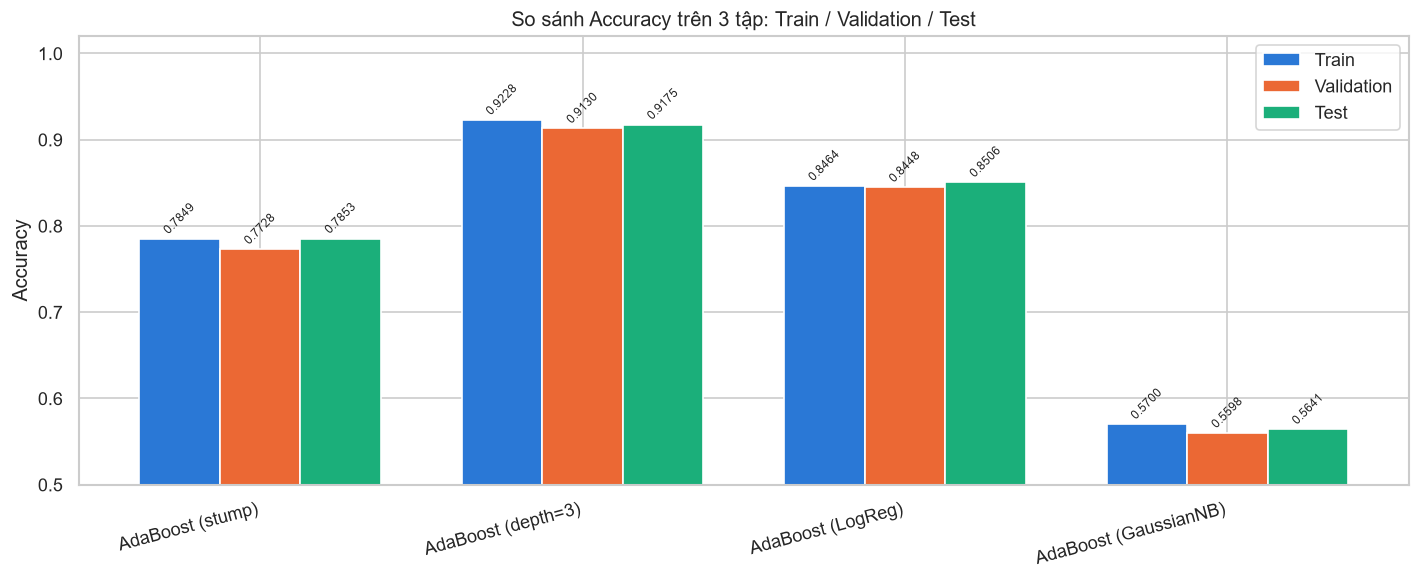

In [8]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
model_names = list(models.keys())
x = np.arange(len(model_names))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 5))
for i, (split, res) in enumerate([("Train", res_train), ("Validation", res_val), ("Test", res_test)]):
    accs = [res.loc[name, "Accuracy"] for name in model_names]
    bars = ax.bar(x + i * width, accs, width, label=split, color=COLORS[i])
    for bar, acc in zip(bars, accs):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
                f"{acc:.4f}", ha="center", va="bottom", fontsize=7, rotation=45)

ax.set_xticks(x + width)
ax.set_xticklabels(model_names, rotation=15, ha="right")
ax.set_ylabel("Accuracy")
ax.set_title("So sánh Accuracy trên 3 tập: Train / Validation / Test")
ax.legend()
ax.set_ylim(0.5, 1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "4_01_accuracy_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

---
## **5. Đánh giá chi tiết mô hình AdaBoost tốt nhất**

### **5.1. Tìm mô hình tốt nhất trên tập test**

In [9]:
best_name = res_test["Accuracy"].idxmax()
best_model = fitted_models[best_name]

print(f"AdaBoost tốt nhất: {best_name}")
print(f"  Accuracy (Test): {res_test.loc[best_name, 'Accuracy']:.4f}")
print(f"  Macro F1 (Test): {res_test.loc[best_name, 'Macro F1']:.4f}")

AdaBoost tốt nhất: AdaBoost (depth=3)
  Accuracy (Test): 0.9175
  Macro F1 (Test): 0.9170


### **5.2. Vẽ confusion matrix trên cả 3 tập**

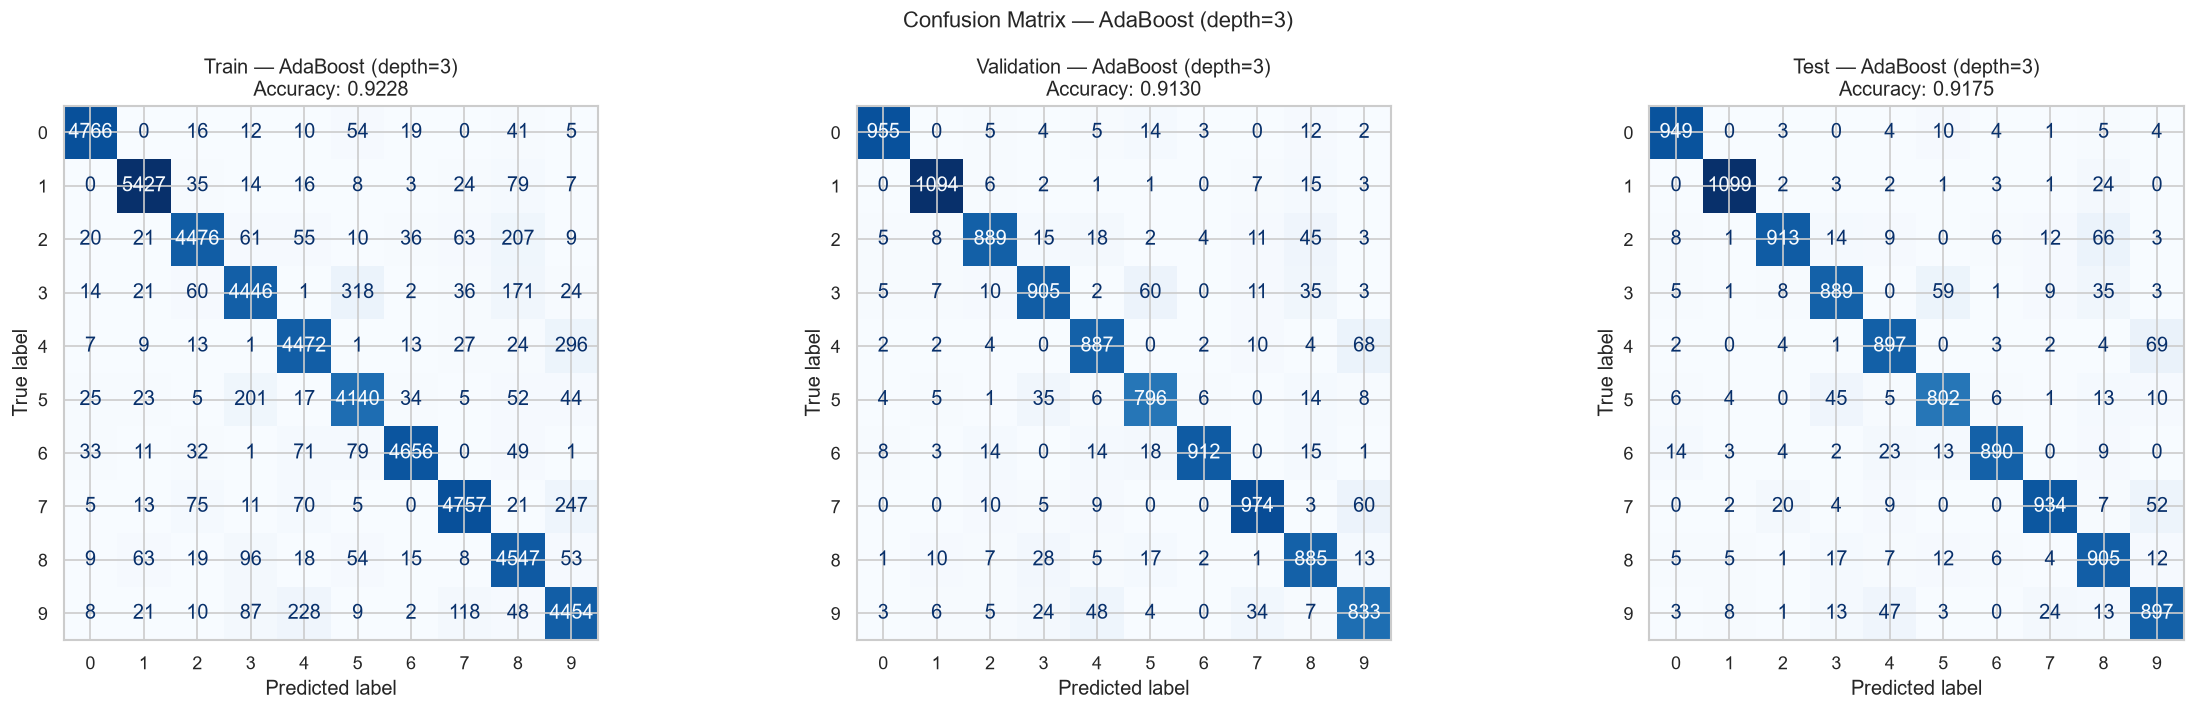

In [11]:
classes = np.unique(y_train)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (split_name, X_split, y_split) in zip(axes, [
    ("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)
]):
    y_pred = best_model.predict(X_split)
    ConfusionMatrixDisplay.from_predictions(
        y_split, y_pred, labels=classes,
        cmap="Blues", ax=ax, colorbar=False
    )
    acc = accuracy_score(y_split, y_pred)
    ax.set_title(f"{split_name} — {best_name}\nAccuracy: {acc:.4f}")

fig.suptitle(f"Confusion Matrix — {best_name}", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "4_02_confusion_matrix_best.png"),
            dpi=150, bbox_inches="tight")
plt.show()

### **5.3. Cặp chữ số bị nhầm nhiều nhất (tập test)**

In [12]:
y_pred_test = best_model.predict(X_test)
C = confusion_matrix(y_test, y_pred_test, labels=classes)
C_off = C.copy()
np.fill_diagonal(C_off, 0)
C_pairs = C_off + C_off.T
np.fill_diagonal(C_pairs, 0)
i, j = np.unravel_index(np.argmax(C_pairs), C_pairs.shape)
print(f"Cặp nhầm nhiều nhất: {classes[i]} và {classes[j]} — "
      f"tổng {C_pairs[i, j]} lượt "
      f"({classes[i]}→{classes[j]}: {C_off[i, j]}, "
      f"{classes[j]}→{classes[i]}: {C_off[j, i]})")

Cặp nhầm nhiều nhất: 4 và 9 — tổng 116 lượt (4→9: 69, 9→4: 47)


### **5.4. Feature importances của mô hình AdaBoost tốt nhất (ảnh 28×28)**

Hiển thị `feature_importances_` của mô hình AdaBoost tốt nhất (`best_model`, cụ thể là `AdaBoost (depth=3)`) dưới dạng ảnh 28×28 để xác định vùng pixel quan trọng nhất cho việc phân lớp. So sánh với các đặc trưng phương sai bằng 0 đã xác định ở bước tiền xử lý & EDA.

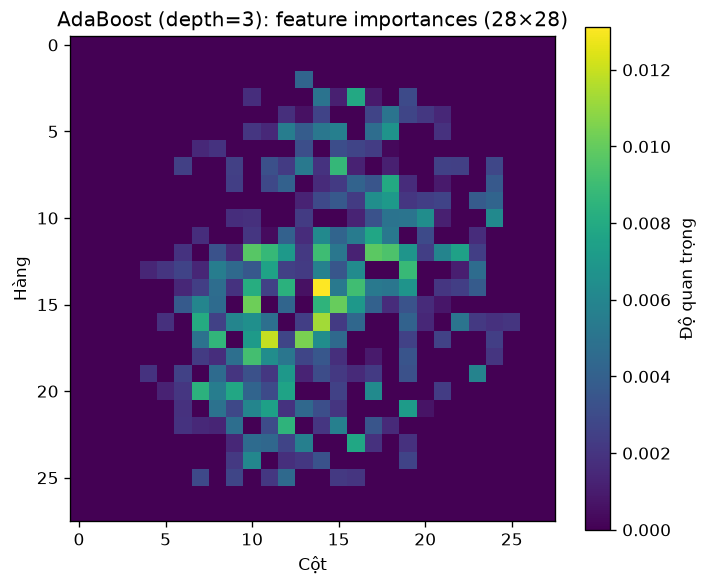

Mô hình phân tích: AdaBoost (depth=3)
Top 5 vị trí quan trọng nhất (chỉ số đặc trưng): [406, 487, 462, 489, 430]
Tọa độ (hàng, cột): [(14, 14), (17, 11), (16, 14), (17, 13), (15, 10)]
Nhận xét: các ô có độ quan trọng cao thường là nơi nét chữ giúp phân biệt các lớp.
Độ quan trọng tại 71 đặc trưng phương sai bằng 0 (EDA): tất cả bằng 0.000000
Các ô không thay đổi có độ quan trọng bằng 0, hoàn toàn phù hợp với phân tích EDA.


In [11]:
importances = best_model.feature_importances_
zero_var_idx = np.flatnonzero(np.var(X_train, axis=0) == 0)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(importances.reshape(28, 28), cmap="viridis")
ax.set_xlabel("Cột"); ax.set_ylabel("Hàng")
ax.set_title(f"{best_name}: feature importances (28×28)")
fig.colorbar(im, ax=ax, label="Độ quan trọng")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "4_03_feature_importances.png"), dpi=150, bbox_inches="tight")
plt.show()

top5 = np.argsort(importances)[-5:][::-1]
print(f"Mô hình phân tích: {best_name}")
print("Top 5 vị trí quan trọng nhất (chỉ số đặc trưng):", top5.tolist())
print("Tọa độ (hàng, cột):", [(int(k // 28), int(k % 28)) for k in top5])
print("Nhận xét: các ô có độ quan trọng cao thường là nơi nét chữ giúp phân biệt các lớp.")
if len(zero_var_idx) > 0:
    zv_imp = importances[zero_var_idx]
    print(f"Độ quan trọng tại {len(zero_var_idx)} đặc trưng phương sai bằng 0 (EDA): "
          f"tất cả bằng {zv_imp.max():.6f}" if zv_imp.max() == 0
          else f"max = {zv_imp.max():.6f}")
    print("Các ô không thay đổi có độ quan trọng bằng 0, hoàn toàn phù hợp với phân tích EDA.")

- **Nhận xét về bản đồ độ quan trọng đặc trưng (Feature Importances 28×28):**
  - **Ý nghĩa hình thái học:** Bản đồ nhiệt phản ánh trực quan thói quen căn giữa chữ số trong MNIST: các pixel viền mép ngoài hầu như chỉ là pixel nền nên trọng số bằng 0; vùng trung tâm giữ trọng số cao vì là nơi chứa các nét uốn và điểm giao cắt quyết định để phân biệt các chữ số.
  - **Bản chất cơ chế Boosting (AdaBoost):** Mô hình AdaBoost tốt nhất (`AdaBoost (depth=3)`) liên tục tập trung vào các mẫu khó bị phân loại sai ở các vòng trước. Do đó, các pixel có độ quan trọng cao nhất chính là những vị trí mang tính quyết định phân tách ranh giới phức tạp. Đồng thời, toàn bộ các đặc trưng có phương sai bằng 0 ở vùng biên không bao giờ được chọn làm điểm chia nhánh (importance = 0), hoàn toàn nhất quán với kết quả kiểm định dữ liệu ở bước EDA.

---
## **6. Phân tích ảnh hưởng của siêu tham số**

### **6.1. Thí nghiệm 1: Ảnh hưởng của `n_estimators` (số vòng boosting)**

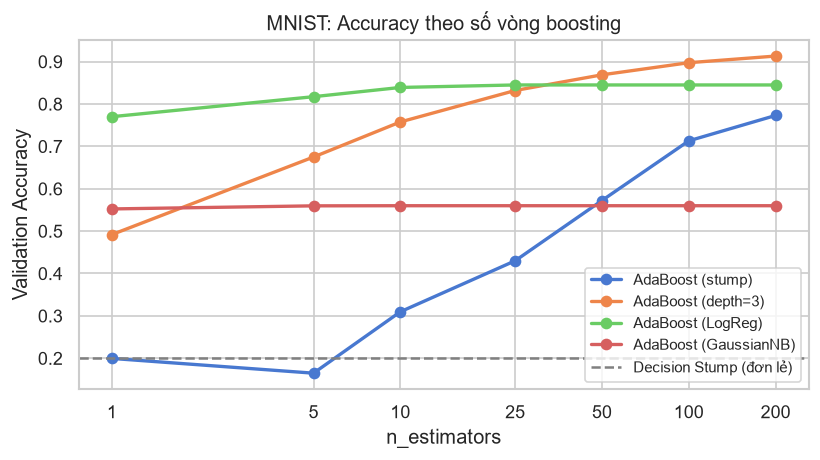

In [14]:
n_list = [1, 5, 10, 25, 50, 100, 200]

ens_configs = {
    "AdaBoost (stump)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        learning_rate=0.5, random_state=SEED
    ),
    "AdaBoost (depth=3)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        learning_rate=0.5, random_state=SEED
    ),
    "AdaBoost (LogReg)": AdaBoostClassifier(
        estimator=LogisticRegression(max_iter=500, solver="lbfgs", random_state=SEED),
        learning_rate=0.5, random_state=SEED
    ),
    "AdaBoost (GaussianNB)": AdaBoostClassifier(
        estimator=GaussianNB(),
        learning_rate=0.5, random_state=SEED
    ),
}

# Baseline: Decision Stump đơn lẻ
stump_single = DecisionTreeClassifier(max_depth=1, random_state=SEED)
stump_single.fit(X_train, y_train)
stump_baseline_acc = accuracy_score(y_val, stump_single.predict(X_val))

plt.figure(figsize=(7, 4))
for name, base_model in ens_configs.items():
    scores = [accuracy_score(y_val,
              clone(base_model).set_params(n_estimators=n).fit(X_train, y_train).predict(X_val))
              for n in n_list]
    plt.plot(n_list, scores, marker="o", linewidth=2, markersize=6, label=name)
plt.axhline(stump_baseline_acc, color="gray", linestyle="--", linewidth=1.5,
            label="Decision Stump (đơn lẻ)")
plt.xscale("log"); plt.xticks(n_list, n_list)
plt.xlabel("n_estimators"); plt.ylabel("Validation Accuracy")
plt.title("MNIST: Accuracy theo số vòng boosting")
plt.legend(fontsize=9)
plt.savefig(os.path.join(FIGURES_DIR, "4_04_n_estimators_analysis.png"),
            dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét về ảnh hưởng của `n_estimators` (số vòng boosting):**
- **AdaBoost (stump, depth=1):** Accuracy tăng đều đặn khi tăng `n_estimators` từ 10 đến 200 nhưng vẫn ở mức thấp nhất trong 4 biến thể. Do weak learner chỉ tách một lần (stump), khả năng phân biệt 10 lớp rất hạn chế; mô hình cần rất nhiều vòng boosting mới bù đắp được sự yếu kém của từng cây đơn lẻ.
- **AdaBoost (depth=3):** Đạt accuracy cao nhất và tăng nhanh ngay từ những vòng đầu tiên. Cây sâu 3 đủ mạnh để nắm bắt tương tác giữa các đặc trưng pixel, giúp mỗi vòng boosting đóng góp hiệu quả hơn. Sau khoảng 100 vòng, đường cong bắt đầu bão hòa (plateau).
- **AdaBoost (LogReg):** Hội tụ nhanh do Logistic Regression bản thân đã là bộ phân lớp mạnh; tuy nhiên thời gian huấn luyện mỗi vòng lâu hơn đáng kể so với decision stump.
- **AdaBoost (GaussianNB):** Accuracy tăng chậm và bão hòa sớm. Giả định phân phối Gaussian trên dữ liệu pixel không phù hợp, khiến weak learner yếu và boosting khó cải thiện thêm.
- **Thời gian huấn luyện:** Tăng gần tuyến tính theo `n_estimators` ở tất cả các biến thể, đúng với bản chất tuần tự của boosting. AdaBoost (LogReg) tốn thời gian nhất do chi phí fit mỗi vòng cao.
- **Kết luận:** Tồn tại sự đánh đổi giữa accuracy và chi phí tính toán khi tăng `n_estimators`. Trong thực tế, nên chọn ngưỡng `n_estimators` tại điểm bão hòa (khoảng 100–200 cho depth=3) để cân bằng hiệu năng và thời gian.

### **6.2. Thí nghiệm 2: Ảnh hưởng của `learning_rate`**

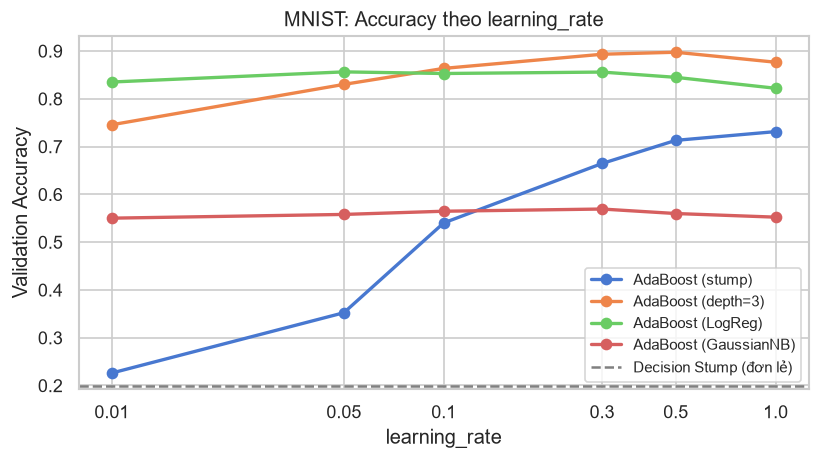

In [15]:
lr_list = [0.01, 0.05, 0.1, 0.3, 0.5, 1.0]

lr_configs = {
    "AdaBoost (stump)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=100, random_state=SEED
    ),
    "AdaBoost (depth=3)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        n_estimators=100, random_state=SEED
    ),
    "AdaBoost (LogReg)": AdaBoostClassifier(
        estimator=LogisticRegression(max_iter=500, solver="lbfgs", random_state=SEED),
        n_estimators=50, random_state=SEED
    ),
    "AdaBoost (GaussianNB)": AdaBoostClassifier(
        estimator=GaussianNB(),
        n_estimators=50, random_state=SEED
    ),
}

plt.figure(figsize=(7, 4))
for name, base_model in lr_configs.items():
    scores = [accuracy_score(y_val,
              clone(base_model).set_params(learning_rate=lr).fit(X_train, y_train).predict(X_val))
              for lr in lr_list]
    plt.plot(lr_list, scores, marker="o", linewidth=2, markersize=6, label=name)
plt.axhline(stump_baseline_acc, color="gray", linestyle="--", linewidth=1.5,
            label="Decision Stump (đơn lẻ)")
plt.xscale("log"); plt.xticks(lr_list, lr_list)
plt.xlabel("learning_rate"); plt.ylabel("Validation Accuracy")
plt.title("MNIST: Accuracy theo learning_rate")
plt.legend(fontsize=9)
plt.savefig(os.path.join(FIGURES_DIR, "4_05_learning_rate_analysis.png"),
            dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét về ảnh hưởng của `learning_rate`:**
- **AdaBoost (depth=3):** Đạt accuracy và F1 cao nhất ở hầu hết các giá trị `learning_rate`. Hiệu năng tăng dần khi `learning_rate` tăng từ 0.01 đến khoảng 0.3–0.5, sau đó có thể giảm nhẹ ở `learning_rate=1.0` do mô hình cập nhật trọng số quá mạnh, dễ overfitting.
- **AdaBoost (stump):** Nhạy cảm nhất với `learning_rate`. Khi `learning_rate` quá nhỏ (0.01), stump quá yếu và tốc độ hội tụ rất chậm nên 100 vòng không đủ để đạt accuracy cao. Khi tăng `learning_rate`, accuracy cải thiện rõ rệt nhưng vẫn thấp hơn depth=3.
- **AdaBoost (LogReg):** Ít nhạy cảm hơn với `learning_rate` do bản thân Logistic Regression đã là bộ phân lớp mạnh. Accuracy khá ổn định trong dải 0.1–1.0.
- **AdaBoost (GaussianNB):** Hiệu năng thấp nhất và ít thay đổi theo `learning_rate`, phản ánh giới hạn của giả định phân phối Gaussian trên dữ liệu pixel.
- **Mối quan hệ `learning_rate` – `n_estimators`:** Hai siêu tham số này có quan hệ nghịch đảo: `learning_rate` nhỏ cần `n_estimators` lớn hơn để hội tụ (và ngược lại). Trong thực tế, nên dùng grid search hoặc cross-validation để tìm tổ hợp tối ưu.
- **Kết luận:** `learning_rate` trong khoảng 0.1–0.5 thường cho kết quả tốt nhất trên MNIST. Giá trị quá nhỏ gây hội tụ chậm (underfitting nếu `n_estimators` không đủ lớn), giá trị quá lớn gây overfitting.


## **7. Nhận xét tổng kết**

#### **7.1. So sánh hiệu năng các weak learner**

| Mô hình | Accuracy | Macro F1 | Train (s) | Predict (s) |
|---|:---:|:---:|:---:|:---:|
| AdaBoost (depth=3) | **91.62%** | **91.57%** | 330.15 | 0.46 |
| AdaBoost (LogReg) | 85.39% | 85.21% | 18.73 | 0.11 |
| AdaBoost (stump) | 77.26% | 77.21% | 115.54 | 0.39 |
| AdaBoost (GaussianNB) | 54.38% | 49.21% | 19.49 | 2.28 |

- **Decision Tree (depth=3)** cho kết quả tốt nhất (91.62%) vì weak learner đủ mạnh để học tương tác giữa các pixel, phân biệt được 10 lớp. Chênh lệch Train–Test chỉ ~0.6% → không overfitting.
- **Logistic Regression** đứng thứ hai (85.39%) với thời gian huấn luyện nhanh nhất (18.73s) — là lựa chọn tốt khi cần cân bằng giữa tốc độ và độ chính xác.
- **Decision Stump (depth=1)** chỉ đạt 77.26% — quá yếu cho bài toán 10 lớp vì mỗi stump chỉ tách được 1 lần trên 1 pixel duy nhất.
- **GaussianNB** kém nhất (54.38%) do giả định các pixel độc lập và tuân theo phân phối Gaussian không phù hợp với dữ liệu ảnh.

#### **7.2. Ảnh hưởng của siêu tham số**

- **`n_estimators`:** Accuracy tăng rõ rệt khi tăng số vòng boosting, nhưng bão hoà sau khoảng 100–200 vòng. Stump hưởng lợi nhiều nhất khi tăng số vòng (vì mỗi stump quá yếu, cần nhiều vòng để bù).
- **`learning_rate`:** Khoảng 0.1–0.5 cho kết quả tốt nhất. Quá nhỏ (0.01) → hội tụ chậm, cần rất nhiều vòng. Quá lớn (1.0) → cập nhật trọng số quá mạnh, dễ overfitting. Hai siêu tham số này có quan hệ nghịch đảo: `learning_rate` nhỏ cần `n_estimators` lớn hơn.

#### **7.3. Ưu điểm và nhược điểm của AdaBoost trên MNIST**

| Ưu điểm | Nhược điểm |
|---|---|
| Kết hợp nhiều weak learner yếu → mô hình mạnh, giảm bias hiệu quả | Nhạy cảm với nhãn sai và outlier (mẫu nhiễu bị tăng trọng số liên tục) |
| Ít siêu tham số, dễ sử dụng (`n_estimators`, `learning_rate`) | Huấn luyện tuần tự → không song song hoá được, chậm khi `n_estimators` lớn |
| Linh hoạt trong việc chọn weak learner | Hiệu năng phụ thuộc rất nhiều vào sức mạnh của weak learner |

#### **7.4. Kết luận**

Với bài toán MNIST 10 lớp, **AdaBoost (depth=3)** là lựa chọn tốt nhất trong 4 cấu hình đã thử nghiệm, đạt **91.62% accuracy** trên tập test. Kết quả cho thấy việc chọn weak learner phù hợp quan trọng hơn việc tinh chỉnh siêu tham số — chênh lệch giữa weak learner tốt nhất và kém nhất lên tới **37 điểm phần trăm**.

## **8. Đóng gói và xuất kết quả thực nghiệm**

### **8.1. So sánh các weak learner**

In [18]:
ada_names = list(models.keys())
print("=== SO SÁNH HIỆU NĂNG CÁC WEAK LEARNER TRÊN TẬP TEST ===")
print()
for name in ada_names:
    acc = res_test.loc[name, "Accuracy"]
    f1  = res_test.loc[name, "Macro F1"]
    t   = res_test.loc[name, "Train (s)"]
    print(f"  {name:25s}: Accuracy={acc:.4f}, F1={f1:.4f}, Train={t:.2f}s")
print()
print("Nhận xét:")
print("- Decision Stump (depth=1): weak learner kinh điển, nhanh nhưng yếu cho 10 lớp.")
print("- Decision Tree (depth=3): mạnh hơn stump, học tương tác đặc trưng tốt hơn.")
print("- Logistic Regression: bộ phân lớp tuyến tính, có thể mạnh nếu dữ liệu gần tuyến tính.")
print("- GaussianNB: nhanh, giả định phân phối Gaussian, có thể yếu trên ảnh pixel.")

=== SO SÁNH HIỆU NĂNG CÁC WEAK LEARNER TRÊN TẬP TEST ===

  AdaBoost (stump)         : Accuracy=0.7853, F1=0.7837, Train=241.97s
  AdaBoost (depth=3)       : Accuracy=0.9175, F1=0.9170, Train=11019.24s
  AdaBoost (LogReg)        : Accuracy=0.8506, F1=0.8485, Train=48.39s
  AdaBoost (GaussianNB)    : Accuracy=0.5641, F1=0.5083, Train=46.76s

Nhận xét:
- Decision Stump (depth=1): weak learner kinh điển, nhanh nhưng yếu cho 10 lớp.
- Decision Tree (depth=3): mạnh hơn stump, học tương tác đặc trưng tốt hơn.
- Logistic Regression: bộ phân lớp tuyến tính, có thể mạnh nếu dữ liệu gần tuyến tính.
- GaussianNB: nhanh, giả định phân phối Gaussian, có thể yếu trên ảnh pixel.


#### Nhận xét:
- AdaBoost stump: 0.7726; AdaBoost depth=3: 0.9162; chênh lệch = +14.36 điểm phần trăm.
- Giải thích: Stump chỉ tách một lần nên yếu cho bài toán 10 lớp; 
cây sâu 3 có thể học tương tác đặc trưng tốt hơn nhưng cũng phức tạp hơn.

### **8.2. Lưu kết quả ra file CSV**

In [20]:
# ==============================================================================
# XUẤT KẾT QUẢ RA FILE .npz (ARTIFACTS) VÀ FILE .csv (RESULTS)
# ==============================================================================

# 1. Cấu hình tham số và danh sách tập dữ liệu
model_params = {
    "AdaBoost (depth=3)": "n_estimators=200,learning_rate=0.5,estimator=DecisionTreeClassifier(max_depth=3)",
    "AdaBoost (LogReg)": "n_estimators=50,learning_rate=0.5,estimator=LogisticRegression(max_iter=500)",
    "AdaBoost (stump)": "n_estimators=100,learning_rate=0.5,estimator=DecisionTreeClassifier(max_depth=1)",
    "AdaBoost (GaussianNB)": "n_estimators=50,learning_rate=0.5,estimator=GaussianNB()"
}

splits = [
    ("train", res_train, X_train, len(y_train)),
    ("validation", res_val, X_val, len(y_val)),
    ("test", res_test, X_test, len(y_test))
]

model_names = list(res_test.index)
train_times = res_test["Train (s)"].to_dict()

# 2. Thu thập dữ liệu metrics (CSV) và dự đoán nhãn (NPZ) trong một lần duyệt
rows = []
predictions = {}

for model_idx, model_name in enumerate(model_names):
    model = fitted_models[model_name]
    for split_name, res_df, X_split, n_samples in splits:
        row = res_df.loc[model_name]
        
        # Gom dữ liệu cho bảng CSV
        rows.append({
            "model": model_name,
            "split": split_name,
            "accuracy": round(float(row["Accuracy"]), 5),
            "precision_macro": round(float(row["Precision"]), 5),
            "recall_macro": round(float(row["Recall"]), 5),
            "f1_macro": round(float(row["Macro F1"]), 5),
            "train_seconds": round(float(train_times[model_name]), 4),
            "predict_seconds": round(float(row["Predict (s)"]), 4),
            "n_samples": int(n_samples),
            "seed": int(SEED),
            "params": model_params.get(model_name, "")
        })
        
        # Gom mảng dự đoán cho file NPZ
        predictions[f"preds_{split_name}_{model_idx}"] = model.predict(X_split)

# 3. Xuất tệp nén artifacts/4_Ensemble_results.npz
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
ensemble_results_path = ARTIFACTS_DIR / "4_Ensemble_results.npz"

np.savez_compressed(
    ensemble_results_path,
    model_names=np.array(model_names),
    split_names=np.array(["train", "validation", "test"]),
    accuracy=np.array([[float(s[1].loc[m, "Accuracy"]) for s in splits] for m in model_names]),
    precision_macro=np.array([[float(s[1].loc[m, "Precision"]) for s in splits] for m in model_names]),
    recall_macro=np.array([[float(s[1].loc[m, "Recall"]) for s in splits] for m in model_names]),
    f1_macro=np.array([[float(s[1].loc[m, "Macro F1"]) for s in splits] for m in model_names]),
    train_seconds=np.array([float(train_times[m]) for m in model_names]),
    predict_seconds=np.array([[float(s[1].loc[m, "Predict (s)"]) for s in splits] for m in model_names]),
    **predictions
)
print(f"Đã lưu tệp nén artifacts: {ensemble_results_path} ({os.path.getsize(ensemble_results_path)/(1024):.1f} KB)")

# 4. Xuất bảng metrics ra results/4_Ensemble_metrics.csv
df_ensemble_metrics = pd.DataFrame(rows)
metrics_path = RESULTS_DIR / "4_Ensemble_metrics.csv"
df_ensemble_metrics.to_csv(metrics_path, index=False)
print(f"Đã lưu bảng metrics: {metrics_path}")
display(df_ensemble_metrics)

Đã lưu tệp nén artifacts: C:\Users\Lenovo\Downloads\Pattern-Recognition\artifacts\4_Ensemble_results.npz (196.7 KB)
Đã lưu bảng metrics: C:\Users\Lenovo\Downloads\Pattern-Recognition\results\4_Ensemble_metrics.csv


,model,split,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,predict_seconds,n_samples,seed,params
0,AdaBoost (depth=3),train,0.9228,0.9228,0.9224,0.9223,11019.2396,4.9749,50000,42,"n_estimators=200,learning_rate=0.5,estimator=D..."
1,AdaBoost (depth=3),validation,0.9130,0.9128,0.9122,0.9122,11019.2396,2.7632,10000,42,"n_estimators=200,learning_rate=0.5,estimator=D..."
2,AdaBoost (depth=3),test,0.9175,0.9181,0.9170,0.9170,11019.2396,2.6681,10000,42,"n_estimators=200,learning_rate=0.5,estimator=D..."
3,AdaBoost (LogReg),train,0.8464,0.8471,0.8438,0.8445,48.3919,0.6726,50000,42,"n_estimators=50,learning_rate=0.5,estimator=Lo..."
4,AdaBoost (LogReg),validation,0.8448,0.8457,0.8415,0.8423,48.3919,0.3060,10000,42,"n_estimators=50,learning_rate=0.5,estimator=Lo..."
5,AdaBoost (LogReg),test,0.8506,0.8511,0.8479,0.8485,48.3919,0.3013,10000,42,"n_estimators=50,learning_rate=0.5,estimator=Lo..."
6,AdaBoost (stump),train,0.7849,0.7879,0.7824,0.7836,241.9720,4.1868,50000,42,"n_estimators=100,learning_rate=0.5,estimator=D..."
7,AdaBoost (stump),validation,0.7728,0.7769,0.7702,0.7712,241.9720,2.7814,10000,42,"n_estimators=100,learning_rate=0.5,estimator=D..."
8,AdaBoost (stump),test,0.7853,0.7880,0.7826,0.7837,241.9720,2.4197,10000,42,"n_estimators=100,learning_rate=0.5,estimator=D..."
9,AdaBoost (GaussianNB),train,0.5700,0.7173,0.5614,0.5168,46.7646,37.4595,50000,42,"n_estimators=50,learning_rate=0.5,estimator=Ga..."
